# Forecast evaluation: models 5-8

1. Load the hourly QC measurements (made in `data_QC_check.ipynb`)
2. Load all forecast files and calculate the forecast horizon
3. Look at forecast vs. measured for some days
4. RMSE and bias for each model and each forecast horizon

In [2]:
import glob
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pvlib

## Settings

In [3]:
station_id = '06123'
latitude = 55.2493     # same values as in data_QC_check.ipynb
longitude = 9.8899

measurement_file = 'dmi_' + station_id + '_hourly_qc.csv'

# Forecast files can be in this folder or in the 'Forecast data' folder
forecast_files = glob.glob(station_id + '_*.csv') + glob.glob('Forecast data/' + station_id + '_*.csv')
forecast_files = sorted(forecast_files)
print('Number of forecast files:', len(forecast_files))

# Models 1-4 are the first four data columns (used in model1_4.ipynb).
# Models 5-8 are the next columns in the forecast files.
models_1_4 = ['dmi_harmonie_arome_europe', 'metno_nordic', 'ecmwf_ifs025', 'ecmwf_aifs025_single']

columns = pd.read_csv(forecast_files[-1], index_col=0, nrows=0).columns
models = list(columns[4:8])
print('Models 5-8:', models)
if len(models) < 4:
    print('NOTE: the newest file only has', len(models), 'columns after models 1-4')

Number of forecast files: 1
Models 5-8: ['gfs_global', 'ecmwf_ifs']
NOTE: the newest file only has 2 columns after models 1-4


## 1. Load the measurements

In [4]:
measured = pd.read_csv(measurement_file, index_col=0)
measured.index = pd.to_datetime(measured.index, utc=True)
measured = measured['ghi']

print('Measurements from', measured.index[0], 'to', measured.dropna().index[-1])

Measurements from 2025-11-01 00:00:00+00:00 to 2026-11-03 15:00:00+00:00


## 2. Load the forecasts

The file name gives the time the forecast was made, e.g. `06123_20261103T1100.csv` was made 2026-11-03 11:00 UTC.

The **forecast horizon** is the time between when the forecast was made and the time it is for:
* forecast made 11:00, timestamp 12:00 (= 11:01–12:00) -> horizon 1 hour
* timestamp 13:00 -> horizon 2 hours, and so on

The files also contain hours before the forecast was made (horizon ≤ 0). These are not real forecasts, so we remove them.

All forecasts are put into one long table with the columns: issue time, time, horizon, model, forecast, measured.

In [5]:
all_rows = []

for file in forecast_files:
    # Forecast issue time from the file name: '06123_20261103T1100.csv' -> '20261103T1100'
    name = os.path.basename(file)
    issue_text = name.replace('.csv', '').split('_')[1]
    issue_time = pd.to_datetime(issue_text, format='%Y%m%dT%H%M', utc=True)

    forecast = pd.read_csv(file, index_col=0)
    forecast.index = pd.to_datetime(forecast.index, utc=True)

    for model in models:
        if model not in forecast.columns:
            continue
        table = pd.DataFrame()
        table['time'] = forecast.index
        table['forecast'] = forecast[model].values
        table['model'] = model
        table['issue_time'] = issue_time
        table['horizon'] = (table['time'] - issue_time) / pd.Timedelta(hours=1)
        all_rows.append(table)

fc = pd.concat(all_rows, ignore_index=True)

# Keep only real forecasts (horizon of 1 hour or more)
fc = fc[fc['horizon'] >= 1]
fc['horizon'] = fc['horizon'].astype(int)

# Add the measured value for the same timestamp
fc['measured'] = measured.reindex(fc['time']).values

fc.head()

,time,forecast,model,issue_time,horizon,measured
12,2026-11-03 12:00:00+00:00,432.0,gfs_global,2026-11-03 11:00:00+00:00,1,140.166667
13,2026-11-03 13:00:00+00:00,222.0,gfs_global,2026-11-03 11:00:00+00:00,2,132.666667
14,2026-11-03 14:00:00+00:00,44.0,gfs_global,2026-11-03 11:00:00+00:00,3,151.166667
15,2026-11-03 15:00:00+00:00,0.0,gfs_global,2026-11-03 11:00:00+00:00,4,43.833333
16,2026-11-03 16:00:00+00:00,0.0,gfs_global,2026-11-03 11:00:00+00:00,5,NaN


### Check: are the new columns real, separate forecasts?
If a column is exactly the same as one of models 1-4, it is probably a copy (e.g. the data source fell back to another model) and should not be counted as an independent model.

In [6]:
for file in forecast_files:
    forecast = pd.read_csv(file, index_col=0)
    for model in models:
        if model not in forecast.columns:
            continue
        for other in models_1_4:
            if other in forecast.columns and forecast[model].equals(forecast[other]):
                print(os.path.basename(file) + ':', model, 'is identical to', other)

06123_20261103T1100.csv: gfs_global is identical to ecmwf_aifs025_single
06123_20261103T1100.csv: ecmwf_ifs is identical to ecmwf_ifs025


### Remove night-time hours
At night both forecast and measurement are 0. Those hours are "perfect" and would make the errors look smaller than they really are, so we only use hours where the sun is up (sun elevation > 0 in the middle of the hour).

In [7]:
middle_of_hour = pd.DatetimeIndex(fc['time']) - pd.Timedelta(minutes=30)
solpos = pvlib.solarposition.get_solarposition(middle_of_hour, latitude, longitude)
fc['elevation'] = solpos['elevation'].values

# Only daytime hours where we have both a forecast and a measurement
data = fc[(fc['elevation'] > 0) & fc['measured'].notna() & fc['forecast'].notna()].copy()
data['error'] = data['forecast'] - data['measured']

print('Forecast/measurement pairs used:', len(data))
print(data.groupby('model').size())

Forecast/measurement pairs used: 8
model
ecmwf_ifs     4
gfs_global    4
dtype: int64


## 3. Forecast vs. measured
This plots the forecast from the newest file that has measurements, along with the measured GHI. Change `file_number` to look at other forecast files.

Issue times with measurements: 1


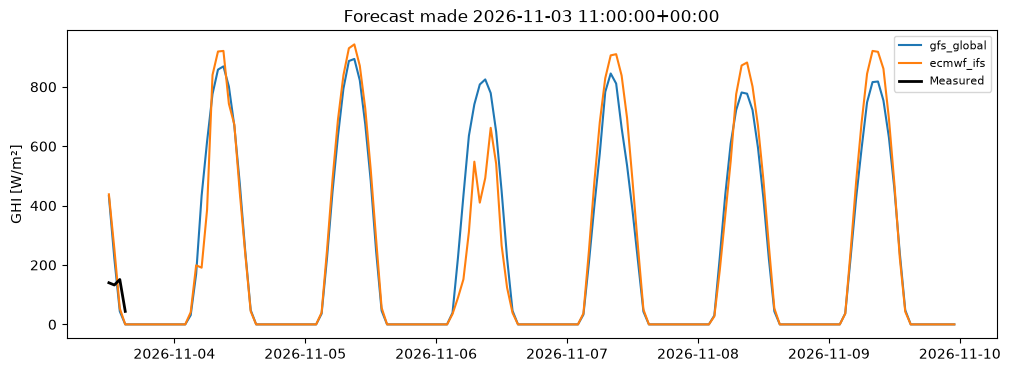

In [8]:
issue_times = sorted(data['issue_time'].unique())
print('Issue times with measurements:', len(issue_times))

file_number = -1        # -1 = newest, 0 = oldest
issue = issue_times[file_number]
one = fc[fc['issue_time'] == issue]

plt.figure(figsize=(12, 4))
for model in models:
    m = one[one['model'] == model]
    plt.plot(m['time'], m['forecast'], label=model)

m = one[one['model'] == models[0]]
plt.plot(m['time'], m['measured'], color='black', linewidth=2, label='Measured')

plt.ylabel('GHI [W/m²]')
plt.title('Forecast made ' + str(issue))
plt.legend(fontsize=8)
plt.show()

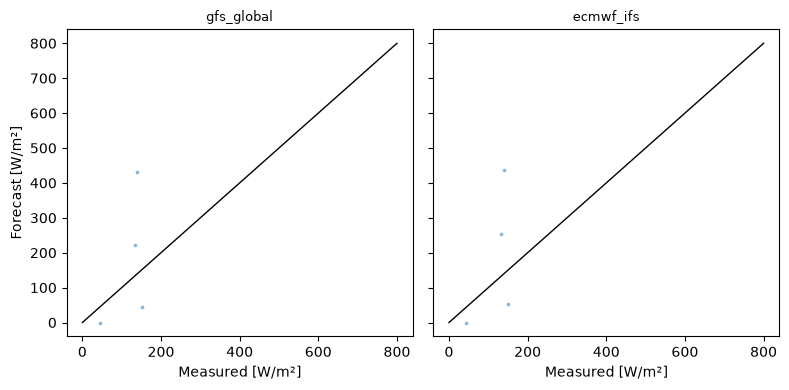

In [9]:
# Scatter plot: forecast vs. measured, one subplot per model
fig, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 4), sharex=True, sharey=True, squeeze=False)
axes = axes[0]

for ax, model in zip(axes, models):
    m = data[data['model'] == model]
    ax.scatter(m['measured'], m['forecast'], s=3, alpha=0.4)
    ax.plot([0, 800], [0, 800], color='black', linewidth=1)   # the 1:1 line
    ax.set_title(model, fontsize=9)
    ax.set_xlabel('Measured [W/m²]')

axes[0].set_ylabel('Forecast [W/m²]')
plt.tight_layout()
plt.show()

## 4. RMSE and bias

* **Bias** = mean(forecast − measured). Positive means the model forecasts too much on average.
* **RMSE** = sqrt(mean((forecast − measured)²)). Large errors count more.

Both are calculated for every model and every forecast horizon. The relative values are divided by the mean measured GHI.

In [10]:
def bias(error):
    return error.mean()

def rmse(error):
    return np.sqrt((error**2).mean())

# Overall scores per model (all horizons together)
overall = data.groupby('model')['error'].agg([bias, rmse])
overall['mean_measured'] = data.groupby('model')['measured'].mean()
overall['rel_bias_%'] = 100 * overall['bias'] / overall['mean_measured']
overall['rel_rmse_%'] = 100 * overall['rmse'] / overall['mean_measured']
overall.round(1)

,bias,rmse,mean_measured,rel_bias_%,rel_rmse_%
model,,,,,
ecmwf_ifs,69.8,169.6,117.0,59.7,145.0
gfs_global,57.5,163.2,117.0,49.2,139.5


In [11]:
# Scores per model and per horizon
scores = data.groupby(['model', 'horizon'])['error'].agg([bias, rmse])
scores['n'] = data.groupby(['model', 'horizon']).size()
scores = scores.reset_index()
scores.head()

,model,horizon,bias,rmse,n
0,ecmwf_ifs,1,297.833333,297.833333,1
1,ecmwf_ifs,2,122.333333,122.333333,1
2,ecmwf_ifs,3,-97.166667,97.166667,1
3,ecmwf_ifs,4,-43.833333,43.833333,1
4,gfs_global,1,291.833333,291.833333,1


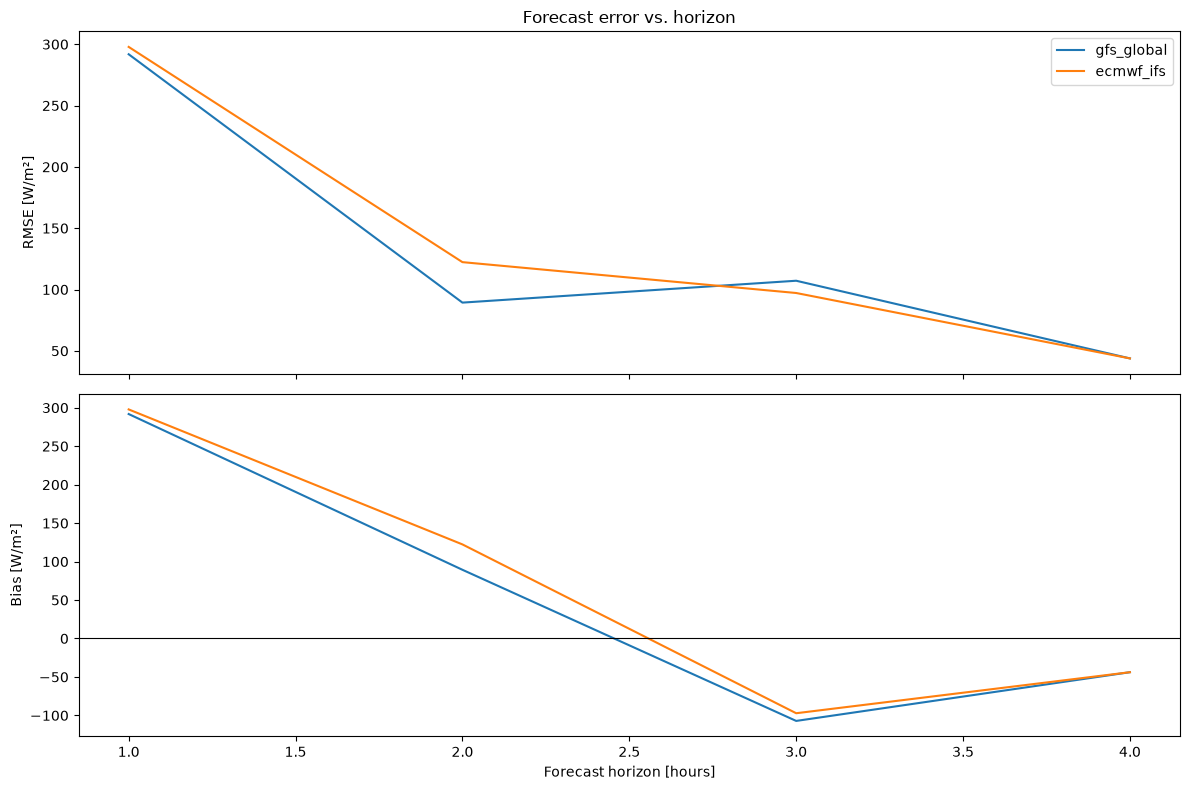

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

for model in models:
    s = scores[scores['model'] == model]
    axes[0].plot(s['horizon'], s['rmse'], label=model)
    axes[1].plot(s['horizon'], s['bias'], label=model)

axes[0].set_ylabel('RMSE [W/m²]')
axes[1].set_ylabel('Bias [W/m²]')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_xlabel('Forecast horizon [hours]')
axes[0].legend()
axes[0].set_title('Forecast error vs. horizon')
plt.tight_layout()
plt.show()

### Per forecast day
One hour horizon only has a few daytime pairs per file, so the curve above is noisy. Grouping the horizons into days (1–24 h = day 1, 25–48 h = day 2, ...) gives a smoother picture.

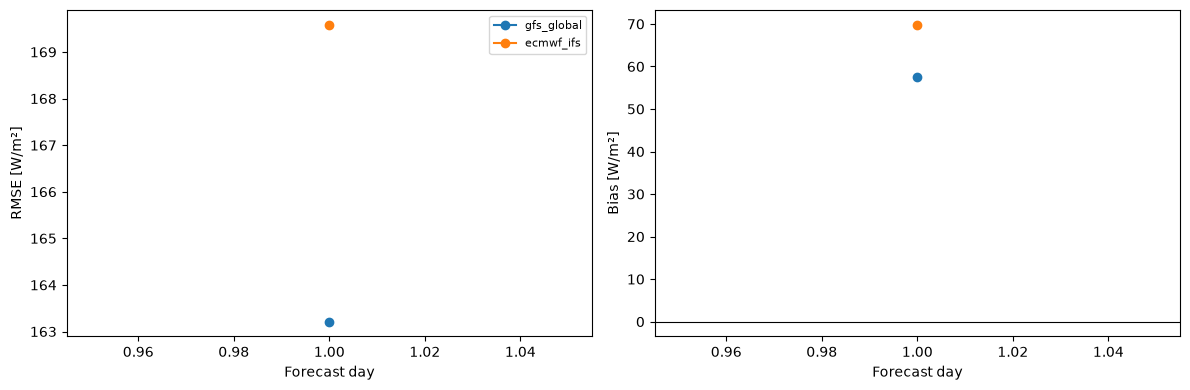

day_ahead,1
model,
ecmwf_ifs,169.6
gfs_global,163.2


In [13]:
data['day_ahead'] = (data['horizon'] - 1) // 24 + 1

daily_scores = data.groupby(['model', 'day_ahead'])['error'].agg([bias, rmse]).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for model in models:
    s = daily_scores[daily_scores['model'] == model]
    axes[0].plot(s['day_ahead'], s['rmse'], marker='o', label=model)
    axes[1].plot(s['day_ahead'], s['bias'], marker='o', label=model)

axes[0].set_ylabel('RMSE [W/m²]')
axes[1].set_ylabel('Bias [W/m²]')
axes[1].axhline(0, color='black', linewidth=0.8)
for ax in axes:
    ax.set_xlabel('Forecast day')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# Table: RMSE per model (rows) and forecast day (columns)
daily_scores.pivot(index='model', columns='day_ahead', values='rmse').round(1)

In [ ]:
# Save the scores so they can be combined with models 1-4 for the poster
# scores.to_csv('scores_models5_8.csv', index=False)
# daily_scores.to_csv('daily_scores_models5_8.csv', index=False)